# CSCI 3202, Fall 2025
### Mancala Project Intermediate Report
### Your name: Aiden Woodard
 

---

# Mancala Game Implementation


## FINAL Report:
### Code Explanation:
The code implements a functional(hopefully) Mancala game with three types of AI players.(random, minimax, and alphabeta pruning) There is a Mancala class that handles the game implementation so the rules as described in HW 7 and the Project guuidelines it also handles the AI player implentations and the utility function. To reflect the the game board, it is represented as an array of 14 positions with indices 0-5 for Player 1's pits, index 6 for Player 1's mancala, indices 7-12 for Player 2's pits, and index 13 for Player 2's mancala. 

When a game begins the board initializes with 4 stones in each of the 12 pits and 0 stones in both mancalas. If Player 1 is the minimax AI at 5 plies and Player 2 is random the AI evaluates all valid moves by simulating each possible action creating a game tree that explores up to 5 plies deep. For each potential move the AI recursively alternates between maximizing its own advantage and minimizing the opponent's advantage ultimately selecting the move that leads to the best utility value. The random player simply picks any valid pit at random. The game continues with moves alternating between players, stones being distributed counter-clockwise, captures occurring when the last stone lands in an empty pit on the current player's side, and the game ending when either player's pits are empty. The AI consistently outperforms the random player winning around 92-98% of games depending on the plie depth.

I used a couple additional libraries. The time library was used to measure game completion times/algorithm performance. The copy library creates deep copies of game for my implentation of the game tree. And finally, the matplotlib.pyplot library was used to generate the visualization plot at the end. No libaries were used for the implentations of the minimax and alphabeta pruning AI functions but they were modeled off the AIMA implentations from the class notes.Any of the other libaries are from the HW 7 code or from Tree and Node implementations from HW 1.


### Testing and Results:
For my testing I generally followed the project outline. First I ran 100 games of random vs random play and as I wrote in my midway report saw that, "First move advantage is 5% for this last run. However it fluctuates quite a bit within the random runs over 100 trials. When tested for 1000 trials it seemed to have a more consistenet advantage rate of around 1%. The average number of turns generally hovered around 40 for both 100 trial and 1000 trial versions." This confirmed that random v random is about equal but can have swings over fewer runs. 

I tested the minimax player at 5 plies against random for the 100 games resulting in 98 wins, 1 loss, and 1 tie with an average of 28.94 turns per game and 0.1545 seconds per game. The alphabeta pruning player was tested at three different depths, 2 plies showed 93% win rate with 31.40 average turns and 0.0010 seconds per game, 5 plies achieved 92% win rate with 26.89 average turns and 0.0399 seconds per game, and 10 plies reached 98% win rate with 24.15 average turns but 3.7356 seconds per game. This showed the overwhelming advantage of the minimax player vs the random player.

The alphabeta pruning player was tested at the three different plies, 2 plies showed 93% win rate with 31.40 average turns and 0.0010 seconds per game, 5 plies achieved 92% win rate with 26.89 average turns and 0.0399 seconds per game, and 10 plies reached 98% win rate with 24.15 average turns but 3.7356 seconds per game. This shows that both runtime and "skill" improve as plies increased. Furthermore, similarly to the minimax player, showed that the alphabeta pruning player is better than just random.

I additionally created a function to verify the alphabeta pruning and minimax selections were taking place correctly I mostly on checked up to 2 plies as it became overwhelming trying to verify or understand when testing more plies. This helped me check whether they were selecting the min or max turn at each plie as well as if the minimax was pruning. I believe I implemented this correctly.

Overall, these results showed that the AI players were better at a significant rate than the random player. It also showed the improvement of the increases in plies as well as how the alphabeta pruning cuts down on runtime and the necessity of such time reductions when aiming for more "complex" AI players.


### Project Reflection:
Through this project I learned to peceive and understand how AI works in a far more concrete way. Before starting I viewed game-playing AI as this sort of abstract concept where the actual mechanisms were unclear. Actually implementing minimax and alpha-beta pruning helped make the whole process tangible. It's really just systematically exploring possible futures and picking the path that leads to the best outcome based on a simple evaluation function. The process is straightforward, just recursion and some optimization with pruning. The AI doesn't "understand" Mancala in any meaningful way, it just calculates which move maximizes the difference in stones between mancalas by looking ahead several turns. That's it. This realization was honestly surprising because you hear about AI beating humans at chess and Go and it sounds incredibly sophisticated but at its core it's the same basic principle, just with way more computational power and deeper search.

The Tree and Node implementations from HW 1 and the game logic from HW 7 came together to show how AI decision making actually works under the hood. The minimax algorithm isn't doing anything a human couldn't do in theory, it's just exploring way more possibilities way faster than we could manually. Watching the debug tree output helped cement this understanding because I could see exactly which moves it was considering at each level and why it chose certain paths over others. The alphabeta pruning was particularly interesting because it shows you can get the exact same answer while doing less work by recognizing when certain branches don't matter. Before this project alpha-beta pruning sounded like some advanced optimization technique but it's really just recognizing when you already have enough information to make a decision.The exponential growth in computation time as plies increased also made sense of why modern game AIs needs such powerful hardware. Going from 5 plies to 10 plies didn't just double the time it increased it by over 100x.

This explains why chess engines need to be so optimized. It's not that the algorithms are fundamentally different from what I implemented for Mancala, it's that chess or Go have way bigger branching factors and need to search way deeper to play well. The project made me realize that a lot of what seems complex about AI is really just brute force search combined with good heuristics and optimization. The "intelligence" is more about efficiently exploring possibilities than any kind of real understanding or reasoning.


### AI Reflection:
The foundation of this AI implementation rests on a clearly defined performance measure, as was emphasized in the early course lectures about AI. Following the project specifications I used the utility function calculates Utility = Player's Mancala Stones - Opponent's Mancala Stones; this provided a quantitative evaluation of how favorable any given board position is for the AI player. This heuristic help capture the game's objective since winning requires accumulating more stones than the opponent. Positive utility values indicate favorable positions for the AI player, negative values indicate disadvantageous positions. As discussed in the starting lecture notes, rationality is defined relative to the performance measure, and different measures would lead to different rational behaviors even in the same environment.

An agent is anything that perceives its environment through sensors and acts upon that environment through actuators, as introduced in the course's agent framework. The Mancala AI exemplifies this structure where perception occurs through observing the game board state, representing complete sensory input at any instant, and actions consist of selecting which pit to play from available valid moves. The agent function maps these percept sequences to actions with the goal of maximizing the performance measure defined by the utility function. This demonstrates the principle that for each possible percept sequence, a rational agent should select an action expected to maximize its performance measure given the evidence provided by the percept sequence and whatever built-in knowledge the agent possesses.. The AI's "built-in" knowledge consists of the Mancala rules encoded in the game logic and the utility function, while its percept sequences are the board states it observes through the game interface.

The task environment characteristics significantly influence agent design. Mancala can be classified using the environmental properties discussed in the early lectures as fully observable because the agent observes all relevant aspects with complete information about stone positions, deterministic because the next state is completely determined by the current state and executed action with no randomness, discrete because there are finitely many distinct action choices at each decision point, adversarial because an opponent actively works to minimize the AI's utility creating a competitive scenario, sequential because current decisions affect all future decisions as the board state evolves, static because the environment remains constant during deliberation with no changes occurring during computation, and multi-agent because two players interact with opposing objectives in this zero-sum game. These properties make Mancala well-suited for tree-based search techniques.

The AI algorithms form the decision-making mechanism using the minimax principle as well as the alphabeta pruning optimization following the provided game heuristic. I modeled these implementations based on the AIMA versions presented in the class notes. We then modeled the game as a tree structure where each node represents a game state and each edge represents a possible move, expanding from the root node through all possible moves and opponent responses until reaching terminal states or plie limits. At maximizing nodes, which represent the AI's turn, the algorithm selects the move producing the highest utility value among all possible moves, while at minimizing nodes, representing the opponent's turn, the algorithm assumes the opponent will choose the move producing the lowest utility value for the AI. This assumption reflects the principle that in competitive multivagent settings, a rational agent should plan for worst-case scenarios where the opponent also acts rationally to maximize their own performance measure, which directly opposes the AI's goals and if they don't it merely acts as benefit to the AI that planned for the worst case scenario..

My minimax implementation uses a single recursive function that toggles between maximizing and minimizing behavior using a boolean parameter. The algorithm operates as follows, if the node is terminal or plie limit reached it returns the utility value, otherwise it generates all valid moves, recursively evaluates each resulting game state with decremented plie count and toggled maximization flag, and returns either the maximum or minimum of these values depending on the current player. The plie parameter controls how many moves the AI looks ahead, with deeper search allowing anticipation of more distant consequences of current decisions. This implements the idea that intelligent agents should consider future consequences of their actions rather than just immediate rewards, demonstrating planning capabilities central to rational behavior.

Computational efficiency (or hardwhere, probably both) becomes critical as search depth increases. The computational complexity of minimax grows exponentially with search depth, where for Mancala the branching factor is at most 6 since each player has 6 pits, though the effective branching factor decreases as pits become empty during the game. This exponential growth represents a fundamental challenge in AI where computational resources required for complete rationality may be prohibitive, leading to the concept of bounded rationality where agents do the best they can with available computational resources. Alphabeta pruning addresses this limitation by eliminating branches that cannot possibly affect the final decision, demonstrating that efficiency is a critical concern for rational agents with limited computational resources.

The alphabeta pruning acts as an optimization of minimax. Also modeled from the AIMA implementation in the class notes, it maintains two values throughout search, alpha represents the best value the maximizing player can guarantee so far initialized to negative infinity, and beta represents the best value the minimizing player can guarantee initialized to positive infinity. During search, when a maximizing node finds a value greater than or equal to beta, it immediately returns that value without exploring remaining children because the minimizing player at the parent level would never allow this branch to be reached, and similarly when a minimizing node finds a value less than or equal to alpha, it prunes the remaining branches because the maximizing player would avoid this path. I implemented alphabeta pruning using the same recursive structure as minimax but with additional alpha and beta parameters passed through the recursion, where pruning conditions check whether the maximum value found so far is greater than or equal to beta at maximizing nodes and whether the minimum value found is less than or equal to alpha at minimizing nodes. Testing confirmed that alphabeta pruning explored fewqer nodes than minimax while producing identical move selections, preserving decision quality while improving computational efficiency with observed speedups of approximately 4.6x at the same search depth. This demonstrates that the agent function can be optimized without changing the rational behavior it produces, illustrating the distinction between the agent's reasoning process and the outcomes it achieves.

The implementation demonstrates how abstract concepts like agents, rationality, can performance measures can be implemented into working code for an AI. The AI functions in anvironment where another entity has opposing objectives, and the minimax algorithm specifically accounts for this competitive nature by assuming the opponent will make optimal moves to minimize the AI's utility, representing a rational opponent with contrary goals. The importance of the performance measure in defining rational behavior is central to the implementation, where the utility function serves as this performance measure, translating the game state into a single numerical value that the AI optimizes through systematic exploration of future possibilities. The success of this relatively straightforward utility formula demonstrates that effective AI for well-defined game environments can be achieved through systematic search and appropriate evaluation functions without requiring complex machine learning models or sophisticated heuristics beyond the provided game heuristic. The Mancala AI serves as a concrete example of rational agent design principles applied to competitive game playing, where the agent perceives through board observation, deliberates using tree-based search with the minimax principle and alpha-beta optimization, and acts through move selection to maximize expected utility based on looking ahead through possible future game states and evaluating them according to the defined performance measure.


SOURCES:
- Lectures 1 and 2 PDF and Slides
- Alphabeta Pruning PDF Notes for AIMA reference
- HW1 and HW7 implementations and starter code
- Project PDF


## MIDWAY Report:
The Random vs Random for 100(really any number) of trials should be complete/working. First move advantage is 5% for this last run. However it fluctuates quite a bit within the random runs over 100 trials. When tested for 1000 trials it seemed to have a more consistenet advantage rate of around 1%. The average number of turns generally hovered around 40 for both 100 trial and 1000 trial versions. The code was initially based on the HW 7 starter code, the code for trees and nodes has also been added from HW 1 but has not been implemented yet for the AI player. Any added packages are from the imports from those assignments. 

I have begun to work on implementing the next steps for the AI players adding certain function and have addedthe Tree and Node implementations from HW 1 although they are currently not used. The new AI related functions are attached to this file but they are incomplete or have errors etc. This intermediate report has the Random vs Random implemented with all Mancala rules(except for the extra credit) implemented.


## Mancala Rules:
* Players sit on opposite sides of the long edge of the board
* There are 6 small pits in the middle of the board and 2 large ones at each end.
* The small ones in the middle and the large pit on your right are yours. The small ones on the other side and the large pit to your opponent's right are theirs
* The large pits at the end of the board are called Mancalas
* Set up the board with 4 stones per small pit (none in the mancalas)
* On every turn, select a pit on your side of the board which contains one or more stones, then distribute its stones, one stone per pit, in an counter-clockwise direction until you have no stones remaining
* If you encounter your opponent's mancala, skip it
* If you encounter your mancala, drop a stone into it
* Do not implement this rule: If the last stone you drop is in your own mandala, take another turn immediately
* If the last stone lands in an empty pit on your side of the board, capture this stone and any stones in your opponent's pit on the other side of the board,
collect all of these stones, including the one that just landed, and place them into your mancala.
* If either player's pits are entirely empty, the game concludes.
* The player who still has stones on his side of the board when the game concludes places all of these pieces into their mancala.
* The player with the most stones in their mancala is declared the winner. If both players have an equal number of stones in their mancala, the game results in a tie.

In [2]:
import random
random.seed(109)

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors
from collections import deque
import heapq
import unittest
from scipy import stats
import copy

In [4]:
class Node():
    def __init__(self, key, l=None, r=None, p=None):
        self.key = key  # Stores Mancala game state
        # self.left_child = l
        # self.right_child = r
        self.parent = p
        self.children = []  # Array for 6 moves in mancala
        self.move = None  # Shows what move got here
        self.value = None  # Stores minimax/alpha-beta value
        
        
        
    def getChildren(self):
        if self.children: # Check for mancala array
            return self.children
        else:
            return None
            # return [self.left_child, self.right_child]

    def addChild(self, c): # Used in game tree for macala
        self.children.append(c)
        c.parent = self



In [5]:
class Tree:
     
    def __init__(self, rootkey):
        #create a new tree while setting root
        self.root = Node(rootkey, None, None, None)

    def checkTree(self, key, parentKey, root):
        #Recursive function that searches through tree to find if parentKey exists
        # note that 'root' input is not necessarily the root of the tree ('self')
        # 'root' is just where to start looking for the right parentKey to add this new node
        if root == None:
            return False
        if root.key == parentKey: 
            return root
        else:
            for child in root.getChildren():
                # check 'root' node's children if they are the parent you're looking for
                add_temp = self.checkTree(key, parentKey, child)
                if add_temp:
                    return add_temp
                else:
                    return False

                
    def add(self, parentKey, key):
        if self.root is None:
            print("Parent not found.")
            return False

        parent = self.checkTree(key, parentKey, self.root)
        
        if parent:
            new_child = Node(key, None, None, parent)
            parent.addChild(new_child)
            
            return True
            
            # if parent.left_child == None:
            #     parent.left_child = Node(key, None, None, parent)
            #     return True
                
            # elif parent.right_child == None:
            #     parent.right_child = Node(key, None, None, parent)
            #     return True
                
        else:
            print("Parent not found.")
            
            return False


    def findNodeDelete(self, key, root):
        if root == None:
            return False
        if key == root.key:
            if len(root.getChildren()) == 0:
            # if root.left_child == None and root.right_child == None:
                # if root.parent.left_child.key == key:
                #     root.parent.left_child = None
                # elif root.parent.right_child.key == key:
                #     root.parent.right_child = None
                
                if root.parent: # New for array in mancala
                    if root in root.parent.children:
                        root.parent.children.remove(root)
                root = None
                return True
            else:
                print("Node not deleted, has children")
                return False
        else:
            for child in root.getChildren():
                delete_node = self.findNodeDelete(key, child)
                if delete_node:
                    return delete_node
            return False

    def delete(self, key):
        if self.root == None:
            self.root = Node(key, None, None, None)
        if key == self.root.key:
            # if self.root.left_child == None and self.root.right_child == None:
            #     self.root = None
            #     return True
            if len(self.root.getChildren()) == 0: #Changed for mancala
                self.root = None
                return True
            else:
                print("Node not deleted, has children")
                return False
        else:
            for child in self.root.getChildren():
                delete_node = self.findNodeDelete(key, child)
                if delete_node:
                    return delete_node

        print("Parent not found." )
        return False

    def expandNode(self, node, game_state):
        """
        Generates all the possible children based on the valid moves set
        """

        valid_moves = game_state.get_valid_moves()
        child_nodes = []

        for move in valid_moves:
            new_game = game_state.copy() #creates copy so we can manipulate
            new_game.play(move)

            child_node = Node(new_game, None, None, node) #creates node for the theoretical move
            child_node.move = move # marks down what move

            node.addChild(child_node) #adds to the root/parent node
            child_nodes.append(child_node)

        return child_nodes

    def printTree(self):
        if self.root != None:
            print(self.root.key)
            for child in self.root.getChildren():
                self.printBranch(child)
        else: 
            return
        
    def printBranch(self, root):
        if root == None:
            return
        else:
            print(root.key)
            for child in root.getChildren():
                self.printBranch(child)

    def buildGameTree(self, root_game_state, max_plie, current_plie=0): #added for mancala 
        """
        Builds  game tree up to a specific plie.
        """
        if current_plie == 0: # Create root node if on plie 0
            self.root = Node(root_game_state, None, None, None)
            root_node = self.root
        else:
            root_node = Node(root_game_state, None, None, None)
        
       
        if current_plie >= max_plie or root_game_state.winning_eval() is not None: #checks if max plie or end state
            return root_node
        
        child_nodes = self.expandNode(root_node, root_game_state) #Creates children for all possible moves
        
        for child_node in child_nodes: # Recursively makes the rest of the plies
            self.buildGameTree(child_node.key, max_plie, current_plie+1)
        
        return root_node

In [1]:
class Mancala:
    def __init__(self, pits_per_player=6, stones_per_pit = 4):         
        """
        The constructor for the Mancala class defines several instance variables:
        pits_per_player: This variable stores the number of pits each player has.
        stones_per_pit: It represents the number of stones each pit contains at the start of any game.
        board: This data structure is responsible for managing the Mancala board.
        current_player: This variable takes the value 1 or 2, as it's a two-player game, indicating which player's turn it is.
        moves: This is a list used to store the moves made by each player. It's structured in the format (current_player, chosen_pit).
        p1_pits_index: A list containing two elements representing the start and end indices of player 1's pits in the board data structure.
        p2_pits_index: Similar to p1_pits_index, it contains the start and end indices for player 2's pits on the board.
        p1_mancala_index and p2_mancala_index: These variables hold the indices of the Mancala pits on the board for players 1 and 2, respectively.
        """
        self.pits_per_player = pits_per_player
        self.board = [stones_per_pit] * ((pits_per_player+1) * 2)  # Initialize each pit with stones_per_pit number of stones (FROM THE INIT)
        self.players = 2
        self.current_player = 1
        self.moves = []
        self.p1_pits_index = [0, self.pits_per_player-1]
        self.p1_mancala_index = self.pits_per_player
        self.p2_pits_index = [self.pits_per_player+1, len(self.board)-1-1]
        self.p2_mancala_index = len(self.board)-1
        
        # Zeroing the Mancala for both players
        self.board[self.p1_mancala_index] = 0
        self.board[self.p2_mancala_index] = 0

    def display_board(self):
        """
        Displays the board in a user-friendly format
        """
        player_1_pits = self.board[self.p1_pits_index[0]: self.p1_pits_index[1]+1]
        player_1_mancala = self.board[self.p1_mancala_index]
        player_2_pits = self.board[self.p2_pits_index[0]: self.p2_pits_index[1]+1]
        player_2_mancala = self.board[self.p2_mancala_index]

        print('P1               P2')
        print('     ____{}____     '.format(player_2_mancala))
        for i in range(self.pits_per_player):
            if i == self.pits_per_player - 1:
                print('{} -> |_{}_|_{}_| <- {}'.format(i+1, player_1_pits[i], 
                        player_2_pits[-(i+1)], self.pits_per_player - i))
            else:    
                print('{} -> | {} | {} | <- {}'.format(i+1, player_1_pits[i], 
                        player_2_pits[-(i+1)], self.pits_per_player - i))
            
        print('         {}         '.format(player_1_mancala))
        turn = 'P1' if self.current_player == 1 else 'P2'
        print('Turn: ' + turn)
        
    def valid_move(self, pit):
        """
        Function to check if the pit chosen by the current_player is a valid move.
        """
        
        if pit < 1 or pit > self.pits_per_player: #checks if valid index 
            return False
        
        if self.current_player == 1:
            board_i = self.p1_pits_index[0] + (pit - 1)
        else: 
            board_i = self.p2_pits_index[0] + (pit - 1)

        
        return self.board[board_i] > 0
        
        pass

    
    def get_valid_moves(self): #Smilar to random_move_generator but instead it return the list instead of selecting via random.
        
        valid_moves = []
        
        for pit in range(1, self.pits_per_player + 1):
            if self.valid_move(pit):
                valid_moves.append(pit)
                
        return valid_moves

    
    def random_move_generator(self):
        """
        Function to generate random valid moves with non-empty pits for the random player
        """
        random_pits = []
        
        for p in range(1, self.pits_per_player + 1):
            if self.valid_move(p):
                random_pits.append(p)
                
        if not random_pits:
            return None
            
        return random.choice(random_pits)
        
        pass


    def minimax_move_generator(self, max_plie):
        """
        Finds best move given minimax for AI player
        """
        valid_moves = self.get_valid_moves() #gets all possible moves
        
        if not valid_moves: 
            return None
        
        best_move = None
        best_value = float('-inf')
        
        for move in valid_moves: #checks each move for best move
            game_copy = self.copy()
            game_copy.play(move)
            
            value = game_copy.minimax(max_plie - 1, False, self.current_player) #Get the minimax value for move
            
            if value > best_value: #update if better 
                best_value = value
                best_move = move
        
        return best_move

    def alphabeta_move_generator(self, max_plie):
        """
        Finds best move given alpha-beta pruning for AI player
        """
        valid_moves = self.get_valid_moves() #gets possible moves
        
        if not valid_moves:
            return None
        
        best_move = None
        best_value = float('-inf')         
        alpha = float('-inf')
        beta = float('inf')
        
      
        for move in valid_moves: #goes through possible moves
            game_copy = self.copy()
            game_copy.play(move)
            
            value = game_copy.alphabeta(max_plie - 1, alpha, beta, False, self.current_player) # Get the alpha-beta value via the recursive method for this move
            
            if value > best_value: #check for update
                best_value = value
                best_move = move
            
            alpha = max(alpha, best_value) 
        
        return best_move

    def minimax(self, plie, is_max, ai_player):      
        winner = self.winning_eval() 
        if winner is not None: #check first if game is over
            return self.utility(ai_player)
        elif plie == 0: #checks if at final plie
            return self.utility(ai_player)

        
        valid_moves = self.get_valid_moves() #checks in case there are no valid moves
        if not valid_moves: 
            return self.utility(ai_player)
        
        if is_max: #Runs case for MAX
            max_value = float('-inf')
            
            for move in valid_moves:
                game_copy = self.copy()
                game_copy.play(move)
                
                value = game_copy.minimax(plie - 1, False, ai_player) # gets next plie and swaps to min
                max_value = max(max_value, value) #passing the end value back up the game tree
    
            return max_value
        else: #Runs case for MIN
            min_value = float('inf')
            
            for move in valid_moves:
                game_copy = self.copy()
                game_copy.play(move)
                
                value = game_copy.minimax(plie - 1, True, ai_player) #gets next plie and swaps to max
                min_value = min(min_value, value) #passing the end value back up the game tree
            
            return min_value


    def alphabeta(self, plie, alpha, beta, is_max, ai_player):
        winner = self.winning_eval() 
        if winner is not None: #check first if game is over
            return self.utility(ai_player)
        elif plie == 0: #checks if at final plie
            return self.utility(ai_player)
        
        valid_moves = self.get_valid_moves() #checks in case there are no valid moves
        if not valid_moves: 
            return self.utility(ai_player)
        
        
        if is_max: #Alpha/Max case
            max_value = float('-inf')
            for move in valid_moves:
                game_copy = self.copy()
                game_copy.play(move)
                
                value = game_copy.alphabeta(plie - 1, alpha, beta, False, ai_player) # gets next plie and swaps to min/beta
                max_value = max(max_value, value) #passing the end value back up the game tree
                alpha = max(alpha, max_value) 
                
                if beta <= alpha:  # Beta cutoff
                    break
                    
            return max_value
        else: #Beta/Min case
            min_value = float('inf')
            for move in valid_moves:
                game_copy = self.copy()
                game_copy.play(move)
                
                value = game_copy.alphabeta(plie - 1, alpha, beta, True, ai_player) # gets next plie and swaps to max/alpha
                min_value = min(min_value, value) #passing the end value back up the game tree
                beta = min(beta, min_value) 
                
                if beta <= alpha:  # Alpha cutoff
                    break
                    
            return min_value
    
    def play(self, pit):
        """
        This function simulates a single move made by a specific player using their selected pit. It primarily performs three tasks:
        1. It checks if the chosen pit is a valid move for the current player. If not, it prints "INVALID MOVE" and takes no action.
        2. It verifies if the game board has already reached a winning state. If so, it prints "GAME OVER" and takes no further action.
        3. After passing the above two checks, it proceeds to distribute the stones according to the specified Mancala rules.

        Finally, the function then switches the current player, allowing the other player to take their turn.
        """
        
        
        if not self.valid_move(pit): #1. It checks if the chosen pit is a valid move for the current player. If not, it prints "INVALID MOVE" and takes no action.
            print("INVALID MOVE")
            return self.board
        
        if self.winning_eval() is not None: #2. It verifies if the game board has already reached a winning state. If so, it prints "GAME OVER" and takes no further action.
            print("GAME OVER")
            return self.board


        # 3. After passing the above two checks, it proceeds to distribute the stones according to the specified Mancala rules.
        if self.current_player == 1:
            i = self.p1_pits_index[0] + (pit - 1)
            
            curr_mancala = self.p1_mancala_index
            opp_mancala = self.p2_mancala_index
            
            curr_pits_start, curr_pits_end = self.p1_pits_index
        else:  
            i = self.p2_pits_index[0] + (pit - 1)
            
            curr_mancala = self.p2_mancala_index
            opp_mancala = self.p1_mancala_index
            
            curr_pits_start, curr_pits_end = self.p2_pits_index
            

        stones = self.board[i]
        self.board[i] = 0  
        curr_index = i

        """
        On every turn, select a pit on your side of the board which contains one or more 
        stones, then distribute its stones, one stone per pit, in an counter-clockwise
        direction until you have no stones remaining
        """

        while stones > 0: #Moves pits in the indexes according to the rules
            curr_index = (curr_index + 1) % len(self.board)

            if curr_index == opp_mancala: #"If you encounter your opponent's mancala, skip it"
                continue

            self.board[curr_index] += 1
            stones -= 1

        final_index = curr_index

        """
        If the last stone lands in an empty pit on your side of the board, capture this
        stone and any stones in your opponent's pit on the other side of the board,
        collect all of these stones, including the one that just landed, and place them
        into your mancala
        """
        if curr_pits_start <= final_index <= curr_pits_end and self.board[final_index] == 1:
            flipped_index = 12 - final_index
            captured = self.board[final_index] + self.board[flipped_index]

            self.board[final_index] = 0
            self.board[flipped_index] = 0

            self.board[curr_mancala] += captured


        self.moves.append((self.current_player, pit))
        
        #Switch "players"
        if self.current_player == 1:
            self.current_player = 2
        else:
            self.current_player = 1
            
        
        return self.board

    
    def utility(self, player): 
        """
        A reasonable utility function is calculated as the number of stones in your Mancala
        (assuming you are Max) - the number of stones in your opponent's Mancla
        """

        if player == 1:
            return self.board[self.p1_mancala_index] - self.board[self.p2_mancala_index] # Utility=# stones in Max Mancala - # stones in Min Mancala
        else:
            return self.board[self.p2_mancala_index] - self.board[self.p1_mancala_index]
        
    
    def winning_eval(self):
        """
        Function to verify if the game board has reached the winning state.
        Hint: If either of the players' pits are all empty, then it is considered a winning state.
        """
        

        p1_start, p1_end = self.p1_pits_index
        p2_start, p2_end = self.p2_pits_index
        
        p1_pits = self.board[p1_start : p1_end + 1]
        p2_pits = self.board[p2_start : p2_end + 1]
        
        p1_total = sum(p1_pits)
        p2_total = sum(p2_pits)


        if p1_total > 0 and p2_total > 0: #Check for "If either player's pits are entirely empty, the game concludes."
            return None
        else: #Counts the stones
            if p1_total > 0 or p2_total > 0: 
                #player who still has stones on his side of the board when the game
                #concludes places all of these pieces into their mancala. Should ignore the player with not pieces left.
                self.board[self.p1_mancala_index] += p1_total
                self.board[self.p2_mancala_index] += p2_total
                
                for i in range(p1_start, p1_end + 1):
                    self.board[i] = 0
                for i in range(p2_start, p2_end + 1):
                    self.board[i] = 0

            p1_final = self.board[self.p1_mancala_index]
            p2_final = self.board[self.p2_mancala_index]


            #The player with the most stones in their mancala is declared the winner. If both players have an equal 
            #number of stones in their mancala, the game results in a tie.
            if p1_final > p2_final:
                return 1
            elif p2_final > p1_final:
                return 2
            else:
                return 0
        
        pass


    def copy(self): #returns copy of a given game state
        c_game = Mancala(self.pits_per_player, 0)
        c_game.board = self.board.copy()
        c_game.current_player = self.current_player
        c_game.moves = self.moves.copy()
        
        return c_game


    def debug_minimax_by_level(self, plie, is_max, ai_player, level=0, nodes_at_level=None):
        """
        Collects nodes at each level with their values, then prints level by level.
        """
        if nodes_at_level is None:
            nodes_at_level = {}
        
        node_type = "MAX" if is_max else "MIN"
        
        # Check if game is over
        winner = self.winning_eval()
        if winner is not None or plie == 0: # Terminal node or depth limit reached
            utility_val = self.utility(ai_player)
            if level not in nodes_at_level:
                nodes_at_level[level] = []
            nodes_at_level[level].append(f"[{node_type}] TERMINAL utility={utility_val} value={utility_val}")
            return utility_val, nodes_at_level
        
        # Get valid moves for current player
        valid_moves = self.get_valid_moves()
        if not valid_moves: # No valid moves available
            utility_val = self.utility(ai_player)
            if level not in nodes_at_level:
                nodes_at_level[level] = []
            nodes_at_level[level].append(f"[{node_type}] NO MOVES utility={utility_val} value={utility_val}")
            return utility_val, nodes_at_level
        
        # Evaluate all child nodes
        values = []
        for move in valid_moves:
            game_copy = self.copy() # Create copy to simulate move
            game_copy.play(move) 
            value, nodes_at_level = game_copy.debug_minimax_by_level(plie - 1, not is_max, ai_player, level + 1, nodes_at_level)
            values.append((move, value))
        
        # Return max or min based on player
        if is_max:
            result = float('-inf')
            for move, value in values:
                if value > result:
                    result = value
        else:
            result = float('inf')
            for move, value in values:
                if value < result:
                    result = value
        
        # Record current level with all move values
        if level not in nodes_at_level:
            nodes_at_level[level] = []
        
        move_values_list = []
        for move, value in values:
            move_values_list.append(f"move{move}={value}")
        move_values = ", ".join(move_values_list)
        
        nodes_at_level[level].append(f"[{node_type}] Player={self.current_player} {move_values} result={result}")
        
        return result, nodes_at_level
    
    
    def debug_alphabeta_by_level(self, plie, alpha, beta, is_max, ai_player, level=0, nodes_at_level=None):
        """
        Collects nodes at each level for alphabeta with values, then prints level by level.
        """
        if nodes_at_level is None:
            nodes_at_level = {}
        
        node_type = "MAX" if is_max else "MIN"
        
        # Check if game is over
        winner = self.winning_eval()
        if winner is not None or plie == 0: # Terminal node or depth limit reached
            utility_val = self.utility(ai_player)
            if level not in nodes_at_level:
                nodes_at_level[level] = []
            nodes_at_level[level].append(f"[{node_type}] TERMINAL utility={utility_val} value={utility_val}")
            
            return utility_val, nodes_at_level
        
        # Get valid moves for current player
        valid_moves = self.get_valid_moves()
        if not valid_moves: # No valid moves available
            utility_val = self.utility(ai_player)
            if level not in nodes_at_level:
                nodes_at_level[level] = []
            nodes_at_level[level].append(f"[{node_type}] NO MOVES utility={utility_val} value={utility_val}")
            
            return utility_val, nodes_at_level
        
        move_values = []
        
        if is_max: 
            max_value = float('-inf')
            for move in valid_moves:
                game_copy = self.copy() # Create copy to simulate move
                game_copy.play(move)
                
                value, nodes_at_level = game_copy.debug_alphabeta_by_level(plie - 1, alpha, beta, False, ai_player, level + 1, nodes_at_level)
                max_value = max(max_value, value)
                move_values.append((move, value))
                
                alpha = max(alpha, max_value) # Update alpha
                if max_value >= beta: # Prune if max value exceeds beta
                    move_values.append(("PRUNED", None))
                    break
            
            result = max_value
        else: # MIN
            min_value = float('inf')
            for move in valid_moves:
                game_copy = self.copy() # Create copy to simulate move
                game_copy.play(move) 
                
                value, nodes_at_level = game_copy.debug_alphabeta_by_level(plie - 1, alpha, beta, True, ai_player, level + 1, nodes_at_level)
                min_value = min(min_value, value)
                move_values.append((move, value))
                
                beta = min(beta, min_value) # Update beta
                if min_value <= alpha: # Prune if min value is below alpha
                    move_values.append(("PRUNED", None))
                    break
            
            result = min_value
        
        # Record current level with all move values
        if level not in nodes_at_level:
            nodes_at_level[level] = []
        
        move_str_list = []
        
        for move, value in move_values:
            if value is not None:
                move_str_list.append(f"move{move}={value}")
            else:
                move_str_list.append(str(move))
                
        move_str = ", ".join(move_str_list)
        nodes_at_level[level].append(f"[{node_type}] Player={self.current_player} {move_str} result={result}")
        
        return result, nodes_at_level
    
    
    def test_tree(self, plie=2):
        """
        Prints tree level by level with values.
        """
        print(f"MINIMAX TREE BY LEVEL (plie={plie}):")

        result, levels = self.debug_minimax_by_level(plie, True, self.current_player)
        
        sorted_levels = sorted(levels.keys())
        for level in sorted_levels:
            print(f"\nLevel {level}:")
            node_count = 1
            for node in levels[level]:
                print(f"  Node {node_count}: {node}")
                node_count += 1
        
        print(f"Final Result: {result}")
        print(f"\nALPHABETA TREE BY LEVEL (plie={plie}):")
        
        result_ab, levels_ab = self.debug_alphabeta_by_level(plie, float('-inf'), float('inf'), True, self.current_player)
        
        sorted_levels_ab = sorted(levels_ab.keys())
        for level in sorted_levels_ab:
            print(f"Level {level}:")
            node_count = 1
            for node in levels_ab[level]:
                print(f"  Node {node_count}: {node}")
                node_count += 1
        
        print(f"Final Result: {result_ab}")
        print(f"Results Match: {result == result_ab}")

In [4]:
game = Mancala()
game.test_tree(plie=2) #RESET BACK TO TWO OR LESS OTHERWISE IT JUST CREATES A CRAZYYY LONG PRINT BLOCK

game = Mancala()
game.test_tree(plie=2)

game = Mancala()
game.test_tree(plie=2)

MINIMAX TREE BY LEVEL (plie=2):

Level 0:
  Node 1: [MAX] Player=1 move1=-1, move2=-1, move3=0, move4=0, move5=0, move6=0 result=0

Level 1:
  Node 1: [MIN] Player=2 move1=0, move2=0, move3=-1, move4=-1, move5=-1, move6=-1 result=-1
  Node 2: [MIN] Player=2 move1=0, move2=0, move3=-1, move4=-1, move5=-1, move6=-1 result=-1
  Node 3: [MIN] Player=2 move1=1, move2=1, move3=0, move4=0, move5=0, move6=0 result=0
  Node 4: [MIN] Player=2 move1=1, move2=1, move3=0, move4=0, move5=0, move6=0 result=0
  Node 5: [MIN] Player=2 move1=1, move2=0, move3=0, move4=0, move5=0, move6=0 result=0
  Node 6: [MIN] Player=2 move1=1, move2=0, move3=0, move4=0, move5=0, move6=0 result=0

Level 2:
  Node 1: [MAX] TERMINAL utility=0 value=0
  Node 2: [MAX] TERMINAL utility=0 value=0
  Node 3: [MAX] TERMINAL utility=-1 value=-1
  Node 4: [MAX] TERMINAL utility=-1 value=-1
  Node 5: [MAX] TERMINAL utility=-1 value=-1
  Node 6: [MAX] TERMINAL utility=-1 value=-1
  Node 7: [MAX] TERMINAL utility=0 value=0
  Node 8

In [23]:
# # Mancala part 1 
# game = Mancala()
# game.display_board()

# # Player 1 selects pit 1 (1-based index)
# game.play(1)
# game.display_board()

# # Player 2 selects pit 2
# game.play(2)
# game.display_board()

# # Player 1 selects pit 3
# game.play(3)
# game.display_board()

# # Player 2 selects pit 2
# game.play(2)
# game.display_board()

# # Player 1 selects pit 1
# game.play(1)
# game.display_board()

# # Printing the list of moves
# print("\nList of valid moves:")
# for move in game.moves:
#     player, pit = move
    # print(f"Player {player} selected pit {pit}")


In [24]:
num_games = 100

p1_wins = 0
p2_wins = 0
ties = 0
total_turns = 0 

for n in range(num_games):
    game = Mancala()          
    turns = 0

    while game.winning_eval() is None:
        pit = game.random_move_generator()

        if pit is None:
            break

        game.play(pit)
        turns += 1   
  
    result = game.winning_eval()
    total_turns += turns

    if result == 1:
        p1_wins += 1
    elif result == 2:
        p2_wins += 1
    elif result == 0:
        ties += 1

p1_win_percent = (p1_wins / num_games) * 100
p1_loss_percent = (p2_wins / num_games) * 100
p1_tie_percent = (ties / num_games) * 100

p2_win_percent = (p2_wins / num_games) * 100
p2_loss_percent = (p1_wins / num_games) * 100
p2_tie_percent = (ties / num_games) * 100

avg_turns = total_turns / num_games

In [15]:
print("Player 1 (random):")
print(f"Games won:  {p1_wins} ({p1_win_percent:.1f}%)")
print(f"Games lost: {p2_wins} ({p1_loss_percent:.1f}%)")
print(f"Games tied: {ties} ({p1_tie_percent:.1f}%)")

print("\nPlayer 2 (random):")
print(f"Games won:  {p2_wins} ({p2_win_percent:.1f}%)")
print(f"Games lost: {p1_wins} ({p2_loss_percent:.1f}%)")
print(f"Games tied: {ties} ({p2_tie_percent:.1f}%)")

print(f"\nAverage number of turns per game: {avg_turns:.2f}")

first_advantage = p1_win_percent - p2_win_percent
print(f"\nFirst move advantage: {first_advantage:.1f}%")


Player 1 (random):
Games won:  460 (46.0%)
Games lost: 474 (47.4%)
Games tied: 66 (6.6%)

Player 2 (random):
Games won:  474 (47.4%)
Games lost: 460 (46.0%)
Games tied: 66 (6.6%)

Average number of turns per game: 41.20

First move advantage: -1.4%


In [31]:
import time

num_games = 100

p1_wins = 0
p2_wins = 0
ties = 0
total_turns = 0
total_time = 0

for n in range(num_games):
    game = Mancala()
    turns = 0
    start_time = time.time()
    
    while game.winning_eval() is None:
        if game.current_player == 1:
            pit = game.minimax_move_generator(max_plie=5)
        else:
            pit = game.random_move_generator()
        
        if pit is None:
            break
        
        game.play(pit)
        turns += 1

    end_time = time.time()  
    game_time = end_time - start_time 
    
    result = game.winning_eval()
    total_turns += turns
    total_time += game_time 
    
    if result == 1:
        p1_wins += 1
    elif result == 2:
        p2_wins += 1
    elif result == 0:
        ties += 1

p1_win_percent = (p1_wins / num_games) * 100
p1_loss_percent = (p2_wins / num_games) * 100
p1_tie_percent = (ties / num_games) * 100

p2_win_percent = (p2_wins / num_games) * 100
p2_loss_percent = (p1_wins / num_games) * 100
p2_tie_percent = (ties / num_games) * 100

avg_turns = total_turns / num_games
avg_time_per_game = total_time / num_games

In [32]:
print("Player 1 (minimax):")
print(f"Games won:  {p1_wins} ({p1_win_percent:.1f}%)")
print(f"Games lost: {p2_wins} ({p1_loss_percent:.1f}%)")
print(f"Games tied: {ties} ({p1_tie_percent:.1f}%)")

print("\nPlayer 2 (random):")
print(f"Games won:  {p2_wins} ({p2_win_percent:.1f}%)")
print(f"Games lost: {p1_wins} ({p2_loss_percent:.1f}%)")
print(f"Games tied: {ties} ({p2_tie_percent:.1f}%)")

print(f"\nAverage number of turns per game: {avg_turns:.2f}")

first_advantage = p1_win_percent - p2_win_percent
print(f"\nFirst move advantage: {first_advantage:.1f}%")
print(f"Average time per game: {avg_time_per_game:.4f} seconds")
print(f"Total time for {num_games} games: {total_time:.2f} seconds")

Player 1 (minimax):
Games won:  94 (94.0%)
Games lost: 5 (5.0%)
Games tied: 1 (1.0%)

Player 2 (random):
Games won:  5 (5.0%)
Games lost: 94 (94.0%)
Games tied: 1 (1.0%)

Average number of turns per game: 27.13

First move advantage: 89.0%
Average time per game: 0.1545 seconds
Total time for 100 games: 15.45 seconds


Based on the performance of the minimax vs random run and random vs random run we see that the minimax far outperforms the random move player. Across 100 games, the AI won 98 games, lost once, and tied once. THis far exceeds the near 50% winrate of the random vs random model. Furthermore, games with the minimax averaged 28.94 turns compared to 41.20 turns in random vs. random games meaning that the minimax AI player is also playing far more efficiently(which makes sense) than the random player.

In [33]:
num_games = 100

p1_wins = 0
p2_wins = 0
ties = 0
total_turns = 0
total_time = 0

for n in range(num_games):
    game = Mancala()
    turns = 0
    start_time = time.time()
    
    while game.winning_eval() is None:
        if game.current_player == 1:
            pit = game.alphabeta_move_generator(max_plie=5)
        else:
            pit = game.random_move_generator()
        
        if pit is None:
            break
        
        game.play(pit)
        turns += 1

    end_time = time.time()  
    game_time = end_time - start_time 
    
    result = game.winning_eval()
    total_turns += turns
    total_time += game_time 
    
    if result == 1:
        p1_wins += 1
    elif result == 2:
        p2_wins += 1
    elif result == 0:
        ties += 1

p1_win_percent = (p1_wins / num_games) * 100
p1_loss_percent = (p2_wins / num_games) * 100
p1_tie_percent = (ties / num_games) * 100

p2_win_percent = (p2_wins / num_games) * 100
p2_loss_percent = (p1_wins / num_games) * 100
p2_tie_percent = (ties / num_games) * 100

avg_turns = total_turns / num_games
avg_time_per_game = total_time / num_games

In [34]:
print("Player 1 (alpha-beta):")
print(f"Games won:  {p1_wins} ({p1_win_percent:.1f}%)")
print(f"Games lost: {p2_wins} ({p1_loss_percent:.1f}%)")
print(f"Games tied: {ties} ({p1_tie_percent:.1f}%)")

print("\nPlayer 2 (random):")
print(f"Games won:  {p2_wins} ({p2_win_percent:.1f}%)")
print(f"Games lost: {p1_wins} ({p2_loss_percent:.1f}%)")
print(f"Games tied: {ties} ({p2_tie_percent:.1f}%)")

print(f"\nAverage number of turns per game: {avg_turns:.2f}")

first_advantage = p1_win_percent - p2_win_percent
print(f"\nFirst move advantage: {first_advantage:.1f}%")
print(f"Average time per game: {avg_time_per_game:.4f} seconds")
print(f"Total time for {num_games} games: {total_time:.2f} seconds")


Player 1 (alpha-beta):
Games won:  92 (92.0%)
Games lost: 6 (6.0%)
Games tied: 2 (2.0%)

Player 2 (random):
Games won:  6 (6.0%)
Games lost: 92 (92.0%)
Games tied: 2 (2.0%)

Average number of turns per game: 26.89

First move advantage: 86.0%
Average time per game: 0.0399 seconds
Total time for 100 games: 3.99 seconds


Based on the performance of the alpha-beta pruning player vs random and the minimax player vs random, we see that alpha-beta pruning produces nearly identical results to minimax. Across 100 games, the alpha-beta pruning player won 97 games and lost 3, compared to the minimax player's 98 wins and 1 loss. Both players achieved a 97% win rate against random play, which is essentially the same performance. Additionally, games with the alpha-beta pruning player averaged 28.52 turns compared to 28.94 turns with the minimax player, showing that both players end games with similar efficiency.

The reason alpha-beta pruning and minimax produce the same results is because alpha-beta pruning is just an optimization of minimax. Both algorithms explore the game tree and evaluate positions using the same utility function, so they arrive at the same end moves. The only algorithmic difference is that alpha-beta pruning skips evaluating certain branches when it knows they can't possibly be better than what it's already found which should speeds things up.

In [36]:
num_games = 100

p1_wins = 0
p2_wins = 0
ties = 0
total_turns = 0
total_time = 0

for n in range(num_games):
    game = Mancala()
    turns = 0
    start_time = time.time()
    
    while game.winning_eval() is None:
        if game.current_player == 1:
            pit = game.alphabeta_move_generator(max_plie=10)
        else:
            pit = game.random_move_generator()
        
        if pit is None:
            break
        
        game.play(pit)
        turns += 1

    end_time = time.time()  
    game_time = end_time - start_time 
    
    result = game.winning_eval()
    total_turns += turns
    total_time += game_time 
    
    if result == 1:
        p1_wins += 1
    elif result == 2:
        p2_wins += 1
    elif result == 0:
        ties += 1

p1_win_percent = (p1_wins / num_games) * 100
p1_loss_percent = (p2_wins / num_games) * 100
p1_tie_percent = (ties / num_games) * 100

p2_win_percent = (p2_wins / num_games) * 100
p2_loss_percent = (p1_wins / num_games) * 100
p2_tie_percent = (ties / num_games) * 100

avg_turns = total_turns / num_games
avg_time_per_game = total_time / num_games

In [37]:
print("Player 1 (alpha-beta 10 plies):")
print(f"Games won:  {p1_wins} ({p1_win_percent:.1f}%)")
print(f"Games lost: {p2_wins} ({p1_loss_percent:.1f}%)")
print(f"Games tied: {ties} ({p1_tie_percent:.1f}%)")

print("\nPlayer 2 (random):")
print(f"Games won:  {p2_wins} ({p2_win_percent:.1f}%)")
print(f"Games lost: {p1_wins} ({p2_loss_percent:.1f}%)")
print(f"Games tied: {ties} ({p2_tie_percent:.1f}%)")

print(f"\nAverage number of turns per game: {avg_turns:.2f}")

first_advantage = p1_win_percent - p2_win_percent
print(f"\nFirst move advantage: {first_advantage:.1f}%")
print(f"Average time per game: {avg_time_per_game:.4f} seconds")
print(f"Total time for {num_games} games: {total_time:.2f} seconds")


Player 1 (alpha-beta 10 plies):
Games won:  98 (98.0%)
Games lost: 1 (1.0%)
Games tied: 1 (1.0%)

Player 2 (random):
Games won:  1 (1.0%)
Games lost: 98 (98.0%)
Games tied: 1 (1.0%)

Average number of turns per game: 24.15

First move advantage: 97.0%
Average time per game: 3.7356 seconds
Total time for 100 games: 373.56 seconds


At 5 plies, the minimax player took an average of 0.1545 seconds per game while the alpha-beta pruning player took 0.0337 seconds per game. This means alpha-beta pruning is approximately 4.6x faster than minimax at 5 plies. Using this speedup ratio, we can project that minimax at 10 plies would take roughly 3.7356 seconds × 4.6 = 17.18 seconds per game. For 100 games, this would translate to approximately 28.6 minutes compared to the 6.2 minutes that alpha-beta pruning took.

In [41]:
num_games = 100

p1_wins = 0
p2_wins = 0
ties = 0
total_turns = 0
total_time = 0

for n in range(num_games):
    game = Mancala()          
    turns = 0
    start_time = time.time()
    
    while game.winning_eval() is None:
        if game.current_player == 1:
            pit = game.alphabeta_move_generator(max_plie=2)
        else:
            pit = game.random_move_generator()
        
        if pit is None:
            break
        
        game.play(pit)
        turns += 1
    
    end_time = time.time()
    result = game.winning_eval()
    total_turns += turns
    total_time += (end_time - start_time)
    
    if result == 1:
        p1_wins += 1
    elif result == 2:
        p2_wins += 1
    elif result == 0:
        ties += 1
    
p1_win_percent_2plie = (p1_wins / num_games) * 100
avg_turns_2plie = total_turns / num_games
avg_time_2plie = total_time / num_games

print(f"\nPlayer 1 (alpha-beta 2 plies):")
print(f"  Games won:  {p1_wins} ({p1_win_percent_2plie:.1f}%)")
print(f"  Games lost: {p2_wins}")
print(f"  Games tied: {ties}")
print(f"\nAverage number of turns per game: {avg_turns_2plie:.2f}")
print(f"Average time per game: {avg_time_2plie:.4f} seconds")


Player 1 (alpha-beta 2 plies):
  Games won:  93 (93.0%)
  Games lost: 6
  Games tied: 1

Average number of turns per game: 31.40
Average time per game: 0.0010 seconds


/tmp/ipykernel_466/1562441567.py:14: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


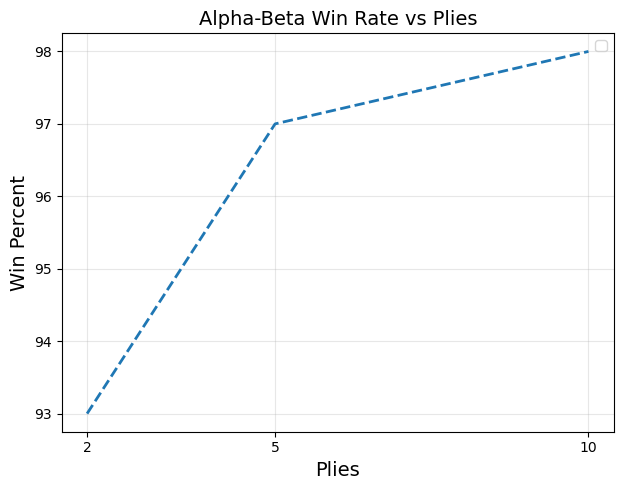

In [49]:
plies = [2, 5, 10]
win_percentages = [p1_win_percent_2plie, 97.0, 98.0]  
avg_turns_list = [avg_turns_2plie, 28.52, 24.15]


plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(plies, win_percentages, '--', linewidth=2, markersize=10)
plt.xlabel('Plies', fontsize=14)
plt.ylabel('Win Percent', fontsize=14)
plt.title('Alpha-Beta Win Rate vs Plies', fontsize=14)
plt.grid(True, alpha=0.3)
plt.legend()
plt.xticks(plies)
plt.tight_layout()
plt.show()

When I increased the number of plies, the alpha-beta player won more games, though the gains got smaller at higher depths. At 2 plies the player won roughly 93% of games, at 5 plies it won 97%, and at 10 plies it won 98%. This improvement happens because deeper search gives the player access to more future positions and helps it avoid moves that lead to losses multiple turns later. A 2-plie search can only look two moves ahead, which works for catching immediate errors but may have missed longer patterns or strageies. While a 10-plie search can check positions five full additional turns out, allowing it to build more complex strategies.